# 01 · Lagos LGA Boundaries

**Project:** Spatio-Temporal Prediction of Pluvial and Coastal Flood Risk in Lagos State, Nigeria
**Notebook:** 01 of the series · **Author:** Utibe Bassey

## Purpose

Every dataset in this project (rainfall, elevation, population, flood records) will be summarised **per Local Government Area (LGA)**. This notebook builds the map that everything else hangs on.

## What this notebook does

1. Loads the Nigeria administrative boundaries downloaded from [GADM](https://gadm.org/download_country.html)
2. Keeps only the 20 LGAs of Lagos State
3. Simplifies the table to two columns: `lga` (name) and `geometry` (shape)
4. Saves a clean file to `data/clean/lagos_lgas.gpkg`
5. Reloads the file and plots it to confirm it is correct

## Inputs and outputs

| | File | Notes |
| --- | --- | --- |
| **Input** | `data/raw/gadm41_NGA.gpkg` | Original GADM download. Never edit raw data |
| **Output** | `data/clean/lagos_lgas.gpkg` | Used by all later notebooks |

## 1. Setup

If a library is missing, install it once from a notebook cell with `%pip install geopandas pyogrio`, then restart the kernel.

In [9]:
# Standard library
from pathlib import Path

# Third-party libraries
import geopandas as gpd           # reads, filters and saves spatial data
import pyogrio                    # fast reader that geopandas uses for GeoPackage files
import matplotlib.pyplot as plt   # plotting

### File paths

This notebook sits in `notebooks/`, so `..` means "go up one folder" to reach `data/`.

In [10]:
RAW_PATH = Path("../data/raw/gadm41_NGA.gpkg")       # original GADM download (do not edit)
CLEAN_PATH = Path("../data/clean/lagos_lgas.gpkg")   # cleaned file created by this notebook

# Stop early, with a clear message, if the raw file cannot be found
assert RAW_PATH.exists(), f"Raw file not found at: {RAW_PATH.resolve()}"

## 2. Load the Nigeria boundaries

A GeoPackage can hold several **layers**. GADM stores one layer per administrative level:

- Level 0: country
- Level 1: state
- Level 2: **LGA** (the level we need)

First, list the layers to confirm the LGA layer name.

In [11]:
# Show every layer in the file (we want the one that ends in _2)
print(pyogrio.list_layers(str(RAW_PATH)))

[['ADM_ADM_0' 'MultiPolygon']
 ['ADM_ADM_1' 'MultiPolygon']
 ['ADM_ADM_2' 'MultiPolygon']]


In [12]:
LGA_LAYER = "ADM_ADM_2"   # LGA level, as shown in the layer list above

# Load all LGAs in Nigeria
nigeria_lgas = gpd.read_file(RAW_PATH, layer=LGA_LAYER)

print(f"LGAs in Nigeria: {len(nigeria_lgas)}")
print("Coordinate system:", nigeria_lgas.crs)   # EPSG:4326 = latitude/longitude in degrees

LGAs in Nigeria: 775
Coordinate system: EPSG:4326


## 3. Filter to Lagos State and clean the table

The GADM table has 14 columns. We only need the LGA name and its shape.

- `NAME_1` holds the state name, which we use to filter
- `NAME_2` holds the LGA name, which we rename to `lga`

> **Tip:** this cell rebuilds `lagos` from `nigeria_lgas` every time, so it is safe to run more than once.

In [13]:
# Keep only the rows for Lagos State
lagos = nigeria_lgas[nigeria_lgas["NAME_1"] == "Lagos"].copy()

# Keep two columns, rename the name column, and reset the row numbers
lagos = (
    lagos[["NAME_2", "geometry"]]
    .rename(columns={"NAME_2": "lga"})
    .reset_index(drop=True)
)

# Lagos State has exactly 20 LGAs
assert len(lagos) == 20, f"Expected 20 LGAs, found {len(lagos)}"

print(f"Lagos LGAs: {len(lagos)}")
print(lagos["lga"].tolist())

Lagos LGAs: 20
['Agege', 'Ajeromi/Ifelodun', 'Alimosho', 'Amuwo Odofin', 'Apapa', 'Badagry', 'Epe', 'Eti-Osa', 'Ibeju-Lekki', 'Ifako/Ijaye', 'Ikeja', 'Ikorodu', 'Kosofe', 'Lagos Island', 'Mainland', 'Mushin', 'Ojo', 'Oshodi/Isolo', 'Shomolu', 'Surulere']


## 4. Save the clean file

The `data/clean` folder is created if it does not exist yet.

In [14]:
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)   # create the folder if needed
lagos.to_file(CLEAN_PATH, driver="GPKG")

print("Saved:", CLEAN_PATH.resolve())

Saved: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\clean\lagos_lgas.gpkg


## 5. Verify the saved file

Reload the file we just wrote and check it contains what we expect.

In [15]:
check = gpd.read_file(CLEAN_PATH)

print("Columns:", check.columns.tolist())   # expect ['lga', 'geometry']
print("Rows:", len(check))                  # expect 20
print("CRS:", check.crs)

# Fail loudly if anything is wrong
assert check.columns.tolist() == ["lga", "geometry"]
assert len(check) == 20
print("All checks passed")

Columns: ['lga', 'geometry']
Rows: 20
CRS: EPSG:4326
All checks passed


## 6. Visualise

The straight southern edge is the Atlantic coast. Epe and Ibeju-Lekki stretch along the east, and the small LGAs of the mainland and the island cluster in the middle.

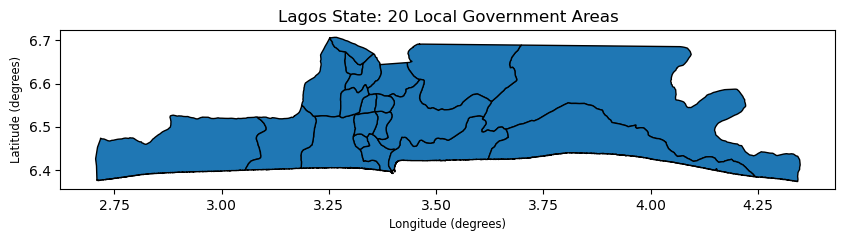

In [16]:
ax = check.plot(edgecolor="black", figsize=(10, 5))
ax.set_title("Lagos State: 20 Local Government Areas")
ax.set_xlabel("Longitude (degrees)")
ax.set_ylabel("Latitude (degrees)")
plt.show()

## Summary

- Loaded the Nigeria LGA boundaries (GADM, level 2) and kept the **20 Lagos LGAs**
- Saved a clean file with two columns, `lga` and `geometry`, to `data/clean/lagos_lgas.gpkg`
- Confirmed the saved file with checks and a map

### Notes for later notebooks

- GADM spells some names differently from other sources. For example, "Mainland" is Lagos Mainland, and "Ajeromi/Ifelodun" and "Ifako/Ijaye" contain slashes. We will **standardise LGA names** when we merge datasets.
- The coordinates are in degrees (EPSG:4326). We will convert to a metric system when we measure distances or areas.

### Next

**`02_rainfall_chirps.ipynb`**: connect to Google Earth Engine and extract daily CHIRPS rainfall for each LGA, 2010-2025.